# Giai đoạn 1: Huấn luyện & Đánh giá Mô hình (Model Training & Evaluation)
## Hệ thống Định hướng Nghề nghiệp CNTT dựa trên Học máy & Khảo sát Học phần

Theo chuẩn vòng đời Model AI trong ứng dụng:
```
[1. Train] ---> [2. Export] ---> [3. Serve] ---> [4. Integrate] ---> [5. Monitor]
```

**Mục tiêu của Notebook này:**
1. **Khảo sát dữ liệu (EDA):** Thống kê mô tả 12 môn học, phân tích phân bố 7 nhóm nghề, ma trận tương quan giữa các học phần.
2. **Tiền xử lý (Preprocessing):** Chuẩn hóa đặc trưng với `StandardScaler`, phân chia tập Train/Test theo phân tầng (`StratifiedKFold`).
3. **Huấn luyện & So sánh mô hình:** Thử nghiệm 3 thuật toán: Logistic Regression (multinomial), Random Forest, Gradient Boosting.
4. **Đánh giá toàn diện:** Đo lường Accuracy, Precision, Recall, F1-Score (Test set) và F1 5-Fold Cross-Validation.
5. **Kết nối Giai đoạn 2 (Export):** Xuất mô hình tốt nhất cùng file siêu dữ liệu vào `models/current/`.

In [15]:
# 1. Khai báo các thư viện cần thiết
from pathlib import Path
import sys
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Tìm thư mục gốc khi mở notebook từ thư mục dự án hoặc thư mục model
PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'career_ai').is_dir() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
from career_ai.domain_knowledge import SUBJECTS, SUBJECT_KEYS, CAREER_GROUPS, LABEL_SOURCE_COL, LABEL_DERIVED
from career_ai.model_exporter import export_model_package
from career_ai.model_calibration import (
    CALIBRATION_FOLDS, CALIBRATION_METHOD, build_calibrated_pipeline,
    evaluate_probability_calibration,
)
from career_ai.train import next_model_version

print("Môi trường và các thư viện đã sẵn sàng.")

Môi trường và các thư viện đã sẵn sàng.


### 1. Khảo sát dữ liệu (Exploratory Data Analysis - EDA)
Đọc tập dữ liệu điểm học phần `data/students.csv` (được trích xuất từ `DATASET.xlsx`).

In [16]:
data_path = PROJECT_ROOT / 'data' / 'students.csv'
df = pd.read_csv(data_path).drop(columns=['name'], errors='ignore')
feature_cols = [SUBJECT_KEYS[s] for s in SUBJECTS]
target_col = 'career_group'

print(f"Tổng số mẫu dữ liệu: {len(df)}")
print(f"Số lượng đặc trưng đầu vào (môn học): {len(feature_cols)}")
print(f"Số lượng nhóm nghề mục tiêu: {df[target_col].nunique()}")
df.head()

Tổng số mẫu dữ liệu: 356
Số lượng đặc trưng đầu vào (môn học): 12
Số lượng nhóm nghề mục tiêu: 7


,sec,se,linux,db,graphics,network,analysis,image,java,csharp,web,ai,career_group,label_source
0,8.8,8.39,9.19,8.89,8.5,8.1,8.8,7.2,8.8,8.4,8.9,9.4,Kiểm thử & Quản lý dự án,derived
1,8.5,6.26,9.29,7.87,9.3,7.3,8.0,6.6,7.6,7.6,9.7,8.8,Phát triển Web,derived
2,7.5,6.45,7.78,6.75,9.0,6.7,3.0,6.8,5.9,7.7,5.9,5.9,Đồ họa & Game,derived
3,7.2,7.87,7.16,8.70,8.5,6.3,7.3,6.5,7.7,5.8,5.9,7.0,Kiểm thử & Quản lý dự án,derived
4,8.5,7.67,9.59,7.60,9.5,7.4,7.6,8.3,7.4,8.5,7.5,7.0,Đồ họa & Game,derived


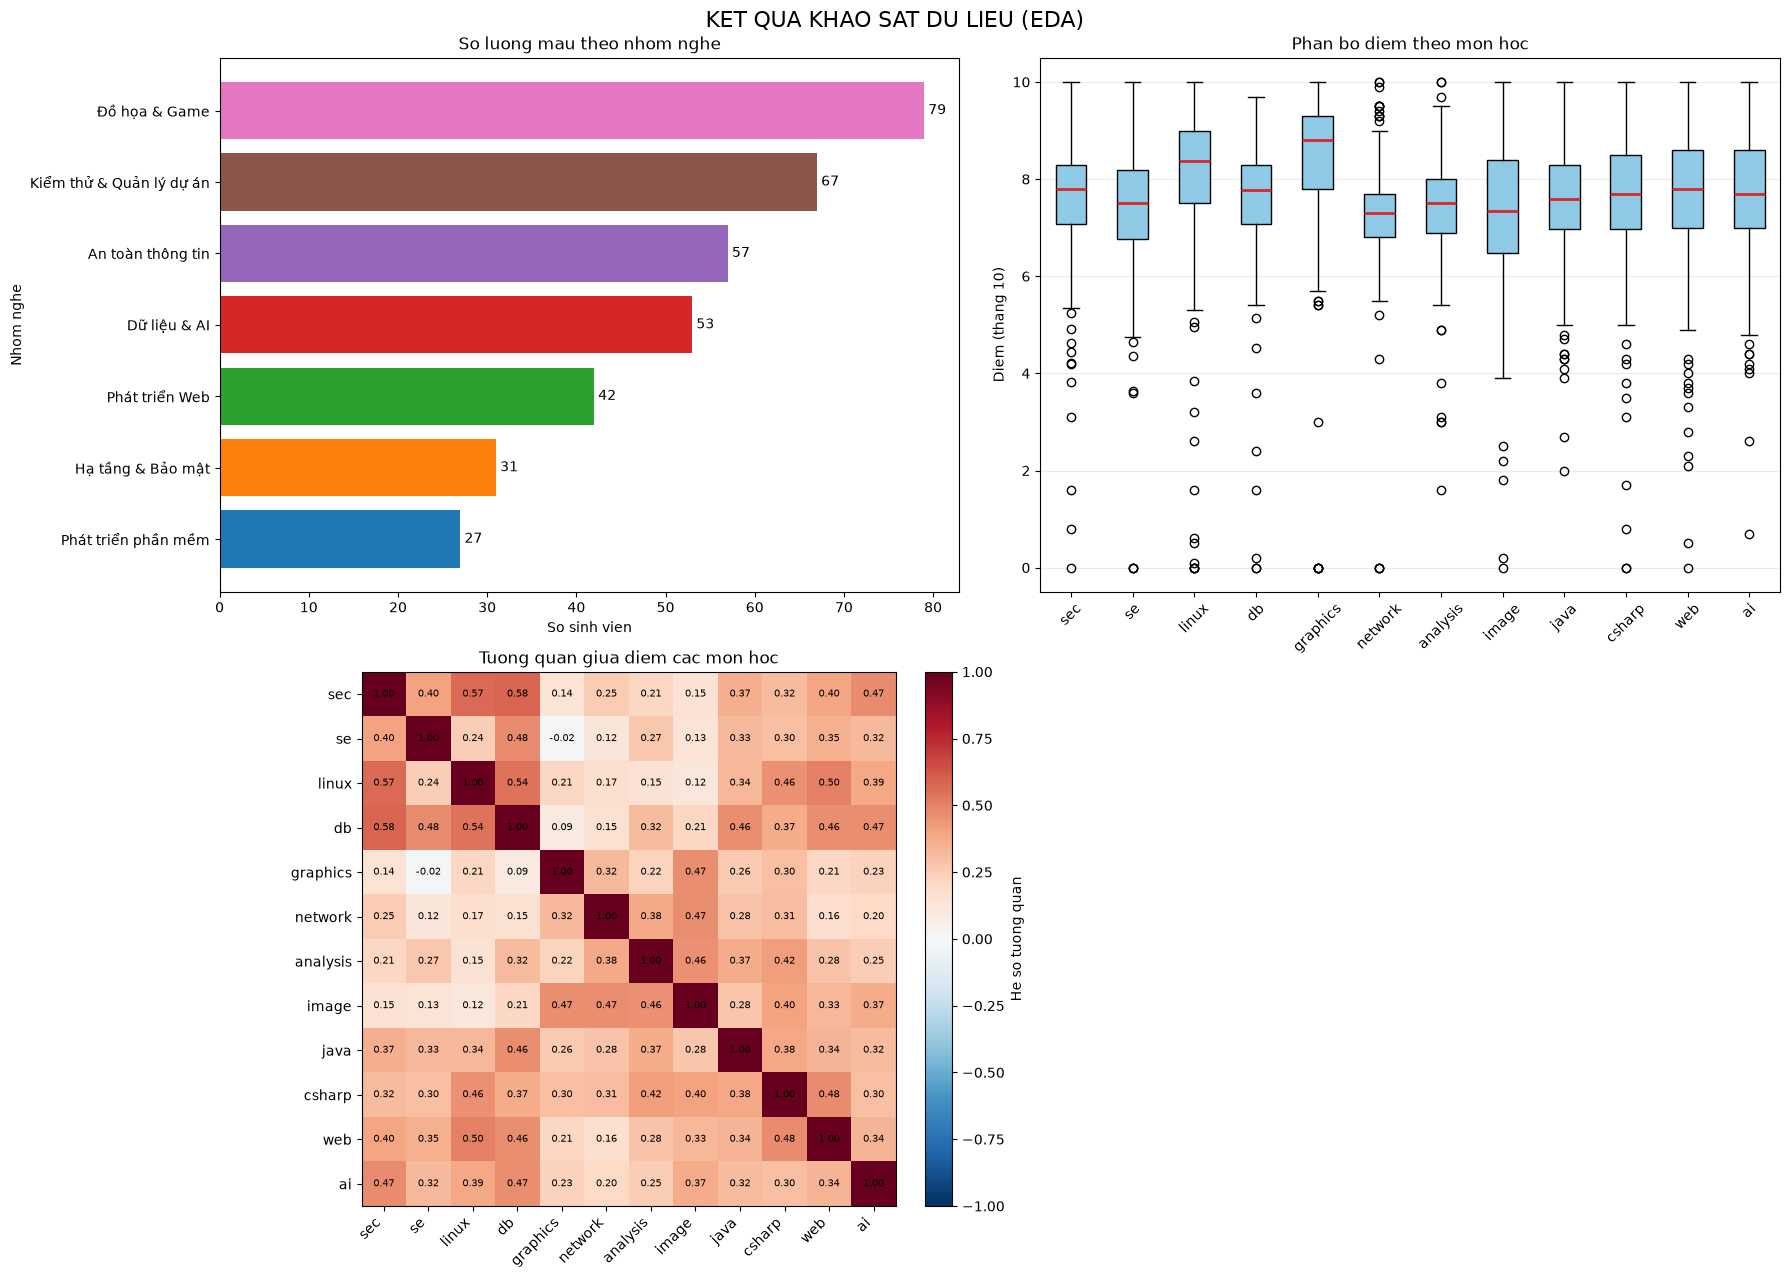

In [17]:
import matplotlib.pyplot as plt

# Ba biểu đồ EDA: phân bố nhóm nghề, phân bố điểm môn học và tương quan giữa các môn.
fig, axes = plt.subplots(2, 2, figsize=(18, 13))

# 1. Số lượng mẫu theo nhóm nghề
counts = df[target_col].value_counts().sort_values(ascending=True)
axes[0, 0].barh(counts.index, counts.values, color=plt.cm.tab10.colors[:len(counts)])
axes[0, 0].set_title('So luong mau theo nhom nghe')
axes[0, 0].set_xlabel('So sinh vien')
axes[0, 0].set_ylabel('Nhom nghe')
for y_pos, value in enumerate(counts.values):
    axes[0, 0].text(value, y_pos, f' {value}', va='center')

# 2. Phân bố điểm theo 12 môn học
axes[0, 1].boxplot(
    [df[col].dropna() for col in feature_cols],
    tick_labels=feature_cols,
    patch_artist=True,
    boxprops={'facecolor': '#8ecae6'},
    medianprops={'color': '#d62828', 'linewidth': 2},
)
axes[0, 1].set_title('Phan bo diem theo mon hoc')
axes[0, 1].set_ylabel('Diem (thang 10)')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(axis='y', alpha=0.25)

# 3. Heatmap hệ số tương quan giữa các môn học
corr = df[feature_cols].corr()
image = axes[1, 0].imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
axes[1, 0].set_title('Tuong quan giua diem cac mon hoc')
axes[1, 0].set_xticks(range(len(feature_cols)), labels=feature_cols, rotation=45, ha='right')
axes[1, 0].set_yticks(range(len(feature_cols)), labels=feature_cols)
for row in range(len(feature_cols)):
    for col in range(len(feature_cols)):
        axes[1, 0].text(col, row, f'{corr.iloc[row, col]:.2f}', ha='center', va='center', fontsize=7)
fig.colorbar(image, ax=axes[1, 0], fraction=0.046, pad=0.04, label='He so tuong quan')

axes[1, 1].axis('off')
fig.suptitle('KET QUA KHAO SAT DU LIEU (EDA)', fontsize=16)
fig.tight_layout()
plt.show()

In [18]:
# Thống kê mô tả (Mean, Std, Min, Max) của 12 môn học
stats_df = df[feature_cols].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats_df['Môn học'] = [SUBJECTS[i] for i, col in enumerate(feature_cols)]
stats_df = stats_df[['Môn học', 'mean', 'std', 'min', '50%', 'max']]
print("=== BẢNG THỐNG KÊ MÔ TẢ ĐIỂM 12 MÔN HỌC ===")
print(stats_df.to_string(index=False))

=== BẢNG THỐNG KÊ MÔ TẢ ĐIỂM 12 MÔN HỌC ===
                      Môn học     mean      std  min  50%  max
      An toàn và bảo mật HTTT 7.607952 1.178248  0.0 7.79 10.0
           Công nghệ phần mềm 7.390244 1.289566  0.0 7.50 10.0
           Hệ điều hành Linux 8.039810 1.597188  0.0 8.38 10.0
             Hệ quản trị CSDL 7.603090 1.203136  0.0 7.77  9.7
     Kỹ thuật đồ hoạ máy tính 8.335112 1.477046  0.0 8.80 10.0
                Mạng máy tính 7.259270 1.060002  0.0 7.30 10.0
      Phân tích thiết kế HTTT 7.440169 1.042445  1.6 7.50 10.0
                    Xử lý ảnh 7.305337 1.418450  0.0 7.35 10.0
               Công nghệ Java 7.567697 1.169228  2.0 7.60 10.0
Ngôn ngữ C# và công nghệ .NET 7.620225 1.376395  0.0 7.70 10.0
                Công nghệ web 7.662079 1.429230  0.0 7.80 10.0
             Trí tuệ nhân tạo 7.670506 1.295453  0.7 7.70 10.0


In [19]:
# Phân bố số lượng sinh viên theo từng nhóm nghề mục tiêu
dist = df[target_col].value_counts()
dist_pct = (df[target_col].value_counts(normalize=True) * 100).round(2)
dist_table = pd.DataFrame({'Số lượng': dist, 'Tỷ lệ (%)': dist_pct})
print("=== PHÂN BỐ NHÓM NGHỀ MỤC TIÊU ===")
print(dist_table)

=== PHÂN BỐ NHÓM NGHỀ MỤC TIÊU ===
                          Số lượng  Tỷ lệ (%)
career_group                                 
Đồ họa & Game                   79      22.19
Kiểm thử & Quản lý dự án        67      18.82
An toàn thông tin               57      16.01
Dữ liệu & AI                    53      14.89
Phát triển Web                  42      11.80
Hạ tầng & Bảo mật               31       8.71
Phát triển phần mềm             27       7.58


In [11]:
# Ma trận tương quan giữa các môn học
corr = df[feature_cols].corr().round(2)
print("Ma trận tương quan giữa các môn học (Correlation Matrix):")
corr

Ma trận tương quan giữa các môn học (Correlation Matrix):


,sec,se,linux,db,graphics,network,analysis,image,java,csharp,web,ai
sec,1.00,0.40,0.57,0.58,0.14,0.25,0.21,0.15,0.37,0.32,0.40,0.47
se,0.40,1.00,0.24,0.48,-0.02,0.12,0.27,0.13,0.33,0.30,0.35,0.32
linux,0.57,0.24,1.00,0.54,0.21,0.17,0.15,0.12,0.34,0.46,0.50,0.39
db,0.58,0.48,0.54,1.00,0.09,0.15,0.32,0.21,0.46,0.37,0.46,0.47
graphics,0.14,-0.02,0.21,0.09,1.00,0.32,0.22,0.47,0.26,0.30,0.21,0.23
network,0.25,0.12,0.17,0.15,0.32,1.00,0.38,0.47,0.28,0.31,0.16,0.20
analysis,0.21,0.27,0.15,0.32,0.22,0.38,1.00,0.46,0.37,0.42,0.28,0.25
image,0.15,0.13,0.12,0.21,0.47,0.47,0.46,1.00,0.28,0.40,0.33,0.37
java,0.37,0.33,0.34,0.46,0.26,0.28,0.37,0.28,1.00,0.38,0.34,0.32
csharp,0.32,0.30,0.46,0.37,0.30,0.31,0.42,0.40,0.38,1.00,0.48,0.30


### 2. Tiền xử lý dữ liệu (Data Preprocessing)
1. Lọc các dòng nhãn suy ra (`derived`) phục vụ so sánh công bằng.
2. Chia tách Train/Test theo tỷ lệ 80/20 với phân tầng (`stratify=y`) để bảo toàn phân bố các nhóm nghề.
3. Xây dựng Pipeline chuẩn hóa với `StandardScaler`.

In [12]:
df_clean = df.dropna(subset=feature_cols + [target_col]).reset_index(drop=True)
X = df_clean[feature_cols]
y = df_clean[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Tập huấn luyện (Train): {X_train.shape[0]} mẫu")
print(f"Tập kiểm thử (Test):     {X_test.shape[0]} mẫu")

Tập huấn luyện (Train): 284 mẫu
Tập kiểm thử (Test):     72 mẫu


### 3. Huấn luyện & So sánh 3 Thuật toán Phân loại
So sánh hiệu năng của:
1. **Logistic Regression (multinomial)**: Tuyến tính đa lớp, có điều chuẩn L2, ổn định cao.
2. **Random Forest**: Tập hợp cây quyết định phân cấp phi tuyến.
3. **Gradient Boosting**: Tối ưu tuần tự gradient descent.

In [13]:
models = {
    "Logistic Regression (multinomial)": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=3, random_state=42
    ),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
comparison_results = []
cv_scores = {}

for name, clf in models.items():
    pipe = Pipeline([("preprocess", StandardScaler()), ("model", clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    cv_pipe = Pipeline([("preprocess", StandardScaler()), ("model", clf)])
    cv_f1 = cross_val_score(cv_pipe, X, y, cv=skf, scoring="f1_weighted").mean()
    cv_scores[name] = cv_f1
    
    comparison_results.append({
        "Thuật toán": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1 (Test)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1 (5-Fold CV)": cv_f1,
    })

res_df = pd.DataFrame(comparison_results)
best_algo = max(cv_scores, key=cv_scores.get)
res_df['Trạng thái triển khai'] = ['<-- TRIỂN KHAI' if a == best_algo else '' for a in res_df['Thuật toán']]
print("=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ===")
print(res_df.to_string(index=False))

=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH ===
                       Thuật toán  Accuracy  Precision   Recall  F1 (Test)  F1 (5-Fold CV) Trạng thái triển khai
Logistic Regression (multinomial)  0.805556   0.798592 0.805556   0.797220        0.867804        <-- TRIỂN KHAI
                    Random Forest  0.736111   0.737375 0.736111   0.733397        0.739257                      
                Gradient Boosting  0.694444   0.695743 0.694444   0.686727        0.669940                      


### 4. Đánh giá Chi tiết Mô hình Triển khai (Classification Report & Confusion Matrix)

In [ ]:
from career_ai.model_calibration import build_calibrated_pipeline
best_pipe = build_calibrated_pipeline(models[best_algo])
best_pipe.fit(X_train, y_train)
y_best_pred = best_pipe.predict(X_test)

print(f"BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) - {best_algo}:")
print(classification_report(y_test, y_best_pred, zero_division=0))

cm = confusion_matrix(y_test, y_best_pred, labels=best_pipe.classes_)
cm_df = pd.DataFrame(cm, index=best_pipe.classes_, columns=best_pipe.classes_)
print("MA TRAN NHAM LAN (CONFUSION MATRIX):")
cm_df


B?O C?O PH?N LO?I CHI TI?T (CLASSIFICATION REPORT) - Logistic Regression (multinomial):
                          precision    recall  f1-score   support

       An toàn thông tin       0.90      0.75      0.82        12
            Dữ liệu & AI       0.71      0.91      0.80        11
       Hạ tầng & Bảo mật       0.83      0.83      0.83         6
Kiểm thử & Quản lý dự án       0.80      0.86      0.83        14
          Phát triển Web       0.86      0.75      0.80         8
     Phát triển phần mềm       0.33      0.20      0.25         5
           Đồ họa & Game       0.88      0.94      0.91        16

                accuracy                           0.81        72
               macro avg       0.76      0.75      0.75        72
            weighted avg       0.80      0.81      0.80        72

MA TR?N NH?M L?N (CONFUSION MATRIX):


,An toàn thông tin,Dữ liệu & AI,Hạ tầng & Bảo mật,Kiểm thử & Quản lý dự án,Phát triển Web,Phát triển phần mềm,Đồ họa & Game
An toàn thông tin,9,0,0,1,0,1,1
Dữ liệu & AI,0,10,1,0,0,0,0
Hạ tầng & Bảo mật,1,0,5,0,0,0,0
Kiểm thử & Quản lý dự án,0,1,0,12,0,1,0
Phát triển Web,0,0,0,1,6,0,1
Phát triển phần mềm,0,2,0,1,1,1,0
Đồ họa & Game,0,1,0,0,0,0,15


### 5. Kết nối Giai đoạn 2 (Export Model + Metadata)
Fit lại mô hình trên toàn bộ dữ liệu hiện có và xuất artifact chuẩn hoá gồm:
- Pipeline tiền xử lý và mô hình (`models/current/model_pipeline.joblib`).
- Siêu dữ liệu cấu hình đầu vào, các ngưỡng giá trị và chỉ số đánh giá (`models/current/metadata.json`).

In [ ]:

calibration_metrics = evaluate_probability_calibration(models[best_algo], X, y, cv=skf)
calibrated_cv = cross_val_score(
    build_calibrated_pipeline(models[best_algo]), X, y,
    cv=skf, scoring="f1_weighted",
)


best_pipe = build_calibrated_pipeline(models[best_algo])
best_pipe.fit(X, y)

metrics_info = {
    "accuracy": accuracy_score(y_test, y_best_pred),
    "precision": precision_score(y_test, y_best_pred, average="weighted", zero_division=0),
    "recall": recall_score(y_test, y_best_pred, average="weighted", zero_division=0),
    "f1_test": f1_score(y_test, y_best_pred, average="weighted", zero_division=0),
    "f1_cv_5fold_mean": float(calibrated_cv.mean()),
    "f1_cv_5fold_std": float(calibrated_cv.std()),
    **calibration_metrics,
    "calibration_method": CALIBRATION_METHOD,
    "calibration_cv_folds": CALIBRATION_FOLDS,
}

exported_meta = export_model_package(
    pipeline=best_pipe,
    algorithm_name=f"{best_algo} + temperature calibration",
    metrics=metrics_info,
    training_df=df_clean,
    version=next_model_version(),
    model_path=str(PROJECT_ROOT / "models" / "current" / "model_pipeline.joblib"),
    metadata_path=str(PROJECT_ROOT / "models" / "current" / "metadata.json"),
    archive=False,
)

print(" DA XUAT THANH CONG ARTIFACT SANG GIAI DOAN 2:")
print(f"  - Phien ban: v{exported_meta['model_version']}")
print(f"  - Thuat toan: {exported_meta['algorithm']}")
print(f"  - So dac trung chuan hoa: {exported_meta['input_schema']['feature_count']}")
print(f"  - F1 5-fold CV: {exported_meta['evaluation_metrics']['f1_cv_5fold_mean']:.3f}")
print(f"  - Brier score: {exported_meta['evaluation_metrics']['brier_score_cv']:.3f}")
print(f"  - Log loss: {exported_meta['evaluation_metrics']['log_loss_cv']:.3f}")


NameError: name 'evaluate_probability_calibration' is not defined